# Before you start

Most of remote sensing starts long before any image is analysed: you need to know **who holds the data**, **how to
get permission**, and **how to download a lot of it reliably**. This notebook walks through the services used most in
Earth observation and climate science, with working code for each, and the habits that make downloads repeatable.

What you will learn:

* the difference between open data that needs no account, data behind a free login, and data you process in the
  cloud instead of downloading;
* where to keep passwords and keys so that they never end up in a notebook, a repository or a screenshot;
* five ways of getting data, each with a real example: a plain web download, a STAC catalogue search, NASA
  Earthdata, the Copernicus data stores (ERA5, GloFAS) and Google Earth Engine;
* how to download in bulk without losing work: one file per request, skipping what is already there, waiting and
  retrying when a server says *too many requests*, checking file sizes and checksums, and keeping a record of every
  file and its licence.

Everything here runs in Google Colab or on your own computer. Cells that need an account check first and explain
what to do if you have not set one up yet, so the notebook runs to the end either way. The outputs shown were made
with real accounts.

**Libraries.** *requests* downloads over the web; *pystac-client* and *planetary-computer* search image catalogues;
*earthaccess* handles NASA Earthdata; *cdsapi* the Copernicus data stores; *earthengine-api* Google Earth Engine;
*xarray* and *netCDF4* read gridded climate files; *pandas* keeps tables; *matplotlib* draws.

In [1]:
import importlib.util, subprocess, sys
need = {"pystac_client": "pystac-client", "planetary_computer": "planetary-computer", "earthaccess": "earthaccess",
        "cdsapi": "cdsapi", "ee": "earthengine-api", "rasterio": "rasterio", "netCDF4": "netCDF4"}
missing = [pkg for mod, pkg in need.items() if importlib.util.find_spec(mod) is None]
if missing:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", *missing], check=True)

import hashlib, json, os, time
from pathlib import Path
import numpy as np
import pandas as pd
import requests
import xarray as xr
import matplotlib.pyplot as plt
plt.rcParams.update({"figure.dpi": 110})
DATA = Path("rs_data")            # everything this notebook downloads goes here
DATA.mkdir(exist_ok=True)
print("Python", sys.version.split()[0], "| data folder:", DATA.resolve().name)

Python 3.12.12 | data folder: rs_data


# Who holds the data

Satellite and climate data are produced by space agencies and weather centres and handed out through **data
portals**. Most are free; many ask you to register so they can count users, apply a licence, and limit how much one
person downloads at once. The table lists the services this guide uses.

| Service | Who runs it | What you get there | Account | How to reach it from code |
|---|---|---|---|---|
| NOAA NCEI | US National Oceanic and Atmospheric Administration | climate data records, e.g. snow cover since 1966 | none | plain web download |
| Microsoft Planetary Computer, Earth Search (AWS) | Microsoft; Element 84 on Amazon | Sentinel-2, Landsat, Copernicus DEM as cloud-optimised files | none for reading | STAC search (*pystac-client*) |
| NASA Earthdata | NASA | MODIS, VIIRS, Landsat, GEDI, ICESat-2, SMAP and more | free login | *earthaccess* |
| Copernicus Data Space Ecosystem | European Space Agency and Commission | all Sentinel missions | free login | STAC, OData, S3 |
| Copernicus Climate Data Store (CDS) | ECMWF for the EU | ERA5 and ERA5-Land reanalysis, satellite climate records | free login + licence per dataset | *cdsapi* |
| Copernicus Early Warning Data Store (EWDS) | ECMWF for the EU | GloFAS river discharge, EFAS, fire danger | same login as CDS + its own terms | *cdsapi* pointed at the EWDS |
| Google Earth Engine | Google | a catalogue of petabytes processed on Google's computers | free for research and teaching, with a Cloud project | *earthengine-api* |
| USGS EarthExplorer | US Geological Survey | Landsat archive, aerial photos, older DEMs | free login | web, or the M2M interface |

**Licences.** Open does not mean without conditions. Copernicus data must be credited ("Contains modified Copernicus
Climate Change Service information [year]"), NASA asks for the dataset's DOI to be cited, and Earth Engine's free tier
is for non-commercial use. Note the licence of every dataset when you download it (the last section shows how).

**Why so many services?** Each agency publishes its own missions. Catalogue standards such as **STAC** and tools such
as *earthaccess* are slowly making them look alike, which is why the same few lines of code now work for many of them.

# Keeping passwords and keys safe

A **password** proves who you are when you log in by hand. Programs instead use a **token** or **API key**: a long
random string the service gives you, which you can cancel at any time without changing your password. Both are
secrets. The rules below are the same in every company and research group.

1. **Never type a secret into a notebook or script.** Notebooks are shared, uploaded and screenshotted; a key in a
   cell will leak.
2. **Keep secrets in a file in your home folder**, which is where the tools look for them anyway:

| Service | File | What it contains |
|---|---|---|
| NASA Earthdata | `~/.netrc` (Windows: `~/_netrc`) | `machine urs.earthdata.nasa.gov login <user> password <password>` |
| Copernicus CDS and EWDS | `~/.cdsapirc` | `url: https://cds.climate.copernicus.eu/api` and `key: <your token>` |
| Google Earth Engine | a credentials file written by `earthengine authenticate` | a refresh token, never typed by you |

3. **Or use environment variables**, which a program reads but which never appear in the code. In Colab, use the
   *Secrets* panel (the key icon) and read them with `google.colab.userdata.get("NAME")`.
4. **Tell git to ignore credential and data files.** Add lines such as `.netrc`, `*.cdsapirc`, `.env` and `rs_data/`
   to `.gitignore`. If a key is ever committed, cancel it on the service's website at once: deleting the commit is
   not enough, because copies already exist.
5. **Print what you got, not how you got it.** A good log says "downloaded 365 files, 1.1 GB"; it never prints the
   key, the full home-folder path or the user name.

The cell below checks which of the three credential files exist on this computer, without reading or printing them.

In [2]:
HOME = Path.home()
creds = {
    "NASA Earthdata (.netrc)": (HOME / ".netrc").exists() or (HOME / "_netrc").exists(),
    "Copernicus CDS/EWDS (.cdsapirc)": (HOME / ".cdsapirc").exists(),
    "Earth Engine (credentials)": (HOME / ".config" / "earthengine" / "credentials").exists(),
}
for name, ok in creds.items():
    print(f"{name:34s} {'found' if ok else 'not set up: the cells that need it will explain and skip'}")
HAVE_EARTHDATA, HAVE_CDS, HAVE_EE = creds.values()

NASA Earthdata (.netrc)            found
Copernicus CDS/EWDS (.cdsapirc)    found
Earth Engine (credentials)         found


# Signing up, step by step

You do this once, by hand, in a web browser. Use your university e-mail: some services give academic users more
capacity, and it makes clear the use is non-commercial.

**NASA Earthdata.** Go to `urs.earthdata.nasa.gov`, choose *Register*, fill in the form and confirm your e-mail. Then
store the login for programs. The simplest way is to let *earthaccess* write the `.netrc` file for you, in a terminal
(not in a shared notebook): `python -c "import earthaccess; earthaccess.login(strategy='interactive', persist=True)"`.
It asks for the user name and password and saves them in your home folder.

**Copernicus Climate Data Store.** Register at `cds.climate.copernicus.eu` (one ECMWF account works for the CDS, the
Atmosphere Data Store and the Early Warning Data Store). Your **API token** is on your profile page. Create the file
`.cdsapirc` in your home folder with two lines, `url: https://cds.climate.copernicus.eu/api` and `key:` followed by the
token. Each dataset has a licence that you accept once on its *Download* tab; a request for a dataset whose licence
you have not accepted fails with a message naming it. The EWDS also has its own terms of use to accept.

**Google Earth Engine.** Go to `earthengine.google.com`, choose *Get started*, and register a Google Cloud project for
non-commercial use (research or teaching). The project's ID (for example `ee-yourname`) is passed to every session.
Then run `earthengine authenticate` once in a terminal, or `ee.Authenticate()` in Colab; a browser window asks you to
allow access and stores a token.

**Copernicus Data Space Ecosystem** (for Sentinel files) is at `dataspace.copernicus.eu`; registration works the same
way. This notebook reads Sentinel-2 through the Planetary Computer instead, which needs no account.

# Method 1: a plain web download

Some data need nothing but a web address. NOAA's **Climate Data Record of Northern Hemisphere snow cover** is one
file, updated weekly, with every week's snow map since October 1966. Three habits make even a single download robust:

* **stream** the file to disk in pieces instead of holding it all in memory;
* **check the size** against what the server announced (the `Content-Length` header), so a broken connection is not
  mistaken for a finished file;
* **write to a temporary name** and rename only when complete, so a half-written file never looks finished.

A **checksum** (here SHA-256) is a short fingerprint of a file's contents; if one byte changes, the fingerprint
changes. Recording it lets anyone confirm later that they have exactly the file you used.

In [3]:
def download(url, dest, chunk=1 << 20, session=None):
    """Download url to dest unless it is already there and complete. Returns (path, size in bytes, sha256)."""
    s = session or requests.Session()
    dest = Path(dest)
    head = s.head(url, allow_redirects=True, timeout=60)
    size = int(head.headers.get("Content-Length", 0))
    if not (dest.exists() and size and dest.stat().st_size == size):
        tmp = dest.with_suffix(dest.suffix + ".part")
        with s.get(url, stream=True, timeout=120) as r:
            r.raise_for_status()
            with open(tmp, "wb") as f:
                for block in r.iter_content(chunk):
                    f.write(block)
        if size and tmp.stat().st_size != size:
            raise IOError(f"incomplete: {tmp.stat().st_size} of {size} bytes")
        tmp.replace(dest)
    h = hashlib.sha256()
    with open(dest, "rb") as f:
        for block in iter(lambda: f.read(chunk), b""):
            h.update(block)
    return dest, dest.stat().st_size, h.hexdigest()

index = requests.get("https://www.ncei.noaa.gov/data/snow-cover-extent/access/", timeout=60).text
name = sorted(set(pd.Series(index.split('"')).loc[lambda s: s.str.startswith("nhsce_") & s.str.endswith(".nc")]))[-1]
path, nbytes, sha = download(f"https://www.ncei.noaa.gov/data/snow-cover-extent/access/{name}", DATA / name)
print(f"{path.name}: {nbytes / 1e6:.1f} MB, sha256 {sha[:16]}...")

nhsce_v01r01_19661004_20261102.nc: 24.7 MB, sha256 c758f2764172f8b9...


Now look inside. The file is **NetCDF**, the usual format for gridded climate data: named variables on named axes
(here time, y and x), with **attributes** that describe units, meanings and the licence. Reading the attributes before
the numbers is a habit worth forming: this one tells us snow is coded 1, no snow 0, and that -127 marks missing weeks.

In [4]:
ds = xr.open_dataset(path, mask_and_scale=False)
v = ds.snow_cover_extent
print(ds.sizes)
print("meaning of values:", dict(zip(v.attrs["flag_values"].tolist(), v.attrs["flag_meanings"].split())))
vals, counts = np.unique(v.values, return_counts=True)
print("values actually present:", dict(zip(vals.tolist(), counts.tolist())), "  <- -127 is not in the list above")
print("licence:", ds.attrs.get("license"), "| cite:", ds.attrs.get("metadata_link"))

Frozen({'x': 88, 'y': 88, 'time': 3135})
meaning of values: {0: 'no_snow', 1: 'snow_covered'}


values actually present: {-127: 286528, 0: 21762862, 1: 2228050}   <- -127 is not in the list above
licence: No restrictions on access or use | cite: https://doi.org/10.7289/V5N014G9


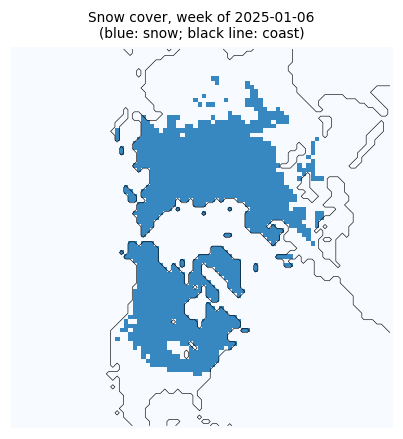

In [5]:
week = v.sel(time="2025-01-06", method="nearest")
fig, ax = plt.subplots(figsize=(4.5, 4.5))
ax.imshow(np.where(week.values < 0, np.nan, week.values), cmap="Blues", vmin=0, vmax=1.5)
ax.contour(ds.land.values, levels=[0.5], colors="black", linewidths=0.4)
ax.set_title(f"Snow cover, week of {str(week.time.values)[:10]}\n(blue: snow; black line: coast)", fontsize=9)
ax.set_axis_off()
plt.show()

# Method 2: searching a STAC catalogue

Large image archives are now described by **STAC**, the SpatioTemporal Asset Catalog standard. A catalogue holds
**collections** (for example Sentinel-2 Level-2A); each collection holds **items** (one image of one place at one
time); each item lists **assets** (one file per band, plus thumbnails and metadata). Because the format is shared, the
same search works on the Planetary Computer, Earth Search, the Copernicus Data Space and many others.

The files are **Cloud-Optimised GeoTIFFs** (COGs): ordinary GeoTIFFs arranged so a program can fetch only the part it
needs over the web. Below we search for Sentinel-2 images of the Hunza valley in the Karakoram and read a small
window of one band without downloading the 100 km tile.

In [6]:
import pystac_client, planetary_computer, rasterio
from rasterio.windows import from_bounds
from rasterio.warp import transform_bounds

catalog = pystac_client.Client.open("https://planetarycomputer.microsoft.com/api/stac/v1",
                                    modifier=planetary_computer.sign_inplace)
BBOX = [74.55, 36.25, 74.75, 36.40]              # west, south, east, north: Karimabad and the Hunza valley
search = catalog.search(collections=["sentinel-2-l2a"], bbox=BBOX, datetime="2025-03-01/2025-04-30",
                        query={"eo:cloud_cover": {"lt": 15}})
items = sorted(search.items(), key=lambda i: i.properties["eo:cloud_cover"])
print(len(items), "images; clearest:", items[0].id, "| cloud", round(items[0].properties["eo:cloud_cover"], 1), "%")
print("assets:", ", ".join(list(items[0].assets)[:16]), "...")

3 images; clearest: S2B_MSIL2A_20250429T054639_R048_T43SDA_20250429T075112 | cloud 0.0 %
assets: AOT, B01, B02, B03, B04, B05, B06, B07, B08, B09, B11, B12, B8A, SCL, WVP, visual ...


In [7]:
item = items[0]
with rasterio.open(item.assets["B03"].href) as src:
    win = from_bounds(*transform_bounds("EPSG:4326", src.crs, *BBOX), src.transform)
    green = src.read(1, window=win)
    print("file CRS:", src.crs, "| pixel size:", src.res, "m | window:", green.shape, "pixels",
          f"(read {green.nbytes / 1e6:.1f} MB of a {src.width} x {src.height} tile)")

file CRS: EPSG:32643 | pixel size: (10.0, 10.0) m | window: (1670, 1801) pixels (read 6.0 MB of a 10980 x 10980 tile)


# Method 3: NASA Earthdata with earthaccess

NASA's archives (at the NSIDC, LP DAAC, GES DISC and others) share one login, **Earthdata Login**, and one search
system, **CMR** (the Common Metadata Repository). The *earthaccess* library wraps both: search needs no login,
download does. Here we look for **MOD10A1F**, MODIS daily snow cover with cloud gaps filled from the last clear view,
for the MODIS tile h24v05 (the Karakoram).

MODIS data come in **tiles** on a sinusoidal grid, named by column (h) and row (v); each tile is about 1,100 km
across and holds 2,400 by 2,400 pixels of 500 m. Files are **HDF4**, an older scientific format holding several named
datasets.

In [8]:
import earthaccess
granules = earthaccess.search_data(short_name="MOD10A1F", version="61", granule_name="*h24v05*",
                                   temporal=("2024-01-01", "2024-01-31"))
sizes = [g.size() for g in granules]
print(len(granules), "daily files for January 2024;", f"{sum(sizes):.0f} MB in total;",
      f"a full year would be about {np.mean(sizes) * 365 / 1000:.1f} GB")
print("first file:", granules[0].data_links()[0].split("/")[-1])

31 daily files for January 2024; 80 MB in total; a full year would be about 0.9 GB
first file: MOD10A1F.A2024001.h24v05.061.2024005105118.hdf


In [9]:
if HAVE_EARTHDATA:
    earthaccess.login(strategy="netrc")
    files = earthaccess.download(granules[:1], str(DATA / "mod10a1f"))
    from pyhdf.SD import SD, SDC
    hdf = SD(str(files[0]), SDC.READ)
    print("datasets in the file:", list(hdf.datasets()))
    snow = hdf.select("CGF_NDSI_Snow_Cover")[:]
    print("array:", snow.shape, snow.dtype)
else:
    print("No Earthdata login on this computer: see 'Signing up, step by step'. Search worked; download skipped.")

QUEUEING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

PROCESSING TASKS | :   0%|          | 0/1 [00:00<?, ?it/s]

COLLECTING RESULTS | :   0%|          | 0/1 [00:00<?, ?it/s]

datasets in the file: ['CGF_NDSI_Snow_Cover', 'Cloud_Persistence', 'Basic_QA', 'Algorithm_Flags_QA', 'MOD10A1_NDSI_Snow_Cover']
array: (2400, 2400) uint8


**Reading the values.** The product stores the **NDSI snow cover**, 0 to 100, and codes above 100 for things that are
not snow measurements: 237 inland water, 239 ocean, 250 cloud (rare here, since gaps were filled), 255 fill. Treating
those codes as numbers is one of the commonest mistakes in remote sensing: always mask them before averaging. The
histogram shows the range of valid values.

coded (non-measurement) values: {237: 17689}


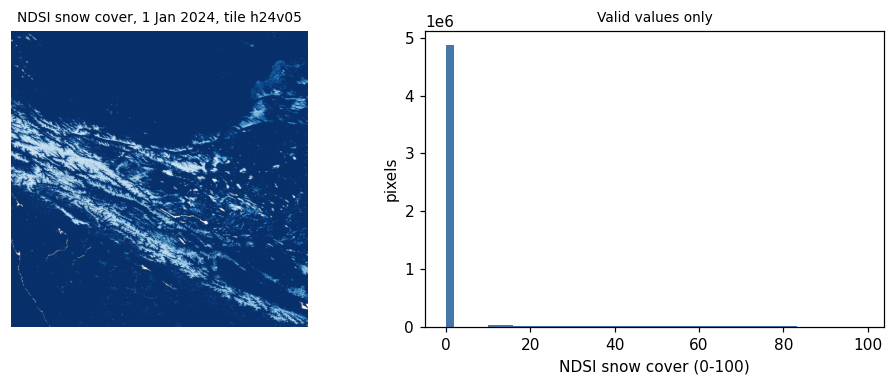

In [10]:
if HAVE_EARTHDATA:
    valid = snow[snow <= 100]
    codes, n = np.unique(snow[snow > 100], return_counts=True)
    print("coded (non-measurement) values:", dict(zip(codes.tolist(), n.tolist())))
    fig, ax = plt.subplots(1, 2, figsize=(9, 3.6))
    ax[0].imshow(np.ma.masked_greater(snow, 100), cmap="Blues_r")
    ax[0].set_title("NDSI snow cover, 1 Jan 2024, tile h24v05", fontsize=9)
    ax[0].set_axis_off()
    ax[1].hist(valid, bins=50, color="#4477aa")
    ax[1].set_xlabel("NDSI snow cover (0-100)")
    ax[1].set_ylabel("pixels")
    ax[1].set_title("Valid values only", fontsize=9)
    plt.tight_layout()
    plt.show()

# Method 4: the Copernicus data stores with cdsapi

ECMWF runs several **data stores** with the same interface: the Climate Data Store (ERA5, ERA5-Land), the Atmosphere
Data Store (air quality) and the Early Warning Data Store (GloFAS river discharge, EFAS). You do not download a file
that already exists: you send a **request** naming the dataset, variables, dates and area, the store builds the file,
and you download it when it is ready. Requests wait in a queue, so large ones can take hours.

**Finding the right options.** Every dataset publishes the combinations it accepts (its *constraints*). Option names
change between versions: in 2025 GloFAS renamed `hyear` to `year` and its discharge variable to
`average_river_discharge_in_the_last_24_hours`, and moved from the CDS to the EWDS. When a request fails with *not a
valid combination*, read the constraints rather than guessing, as the next cell does.

In [11]:
meta = requests.get("https://ewds.climate.copernicus.eu/api/catalogue/v1/collections/cems-glofas-historical", timeout=60).json()
link = next(l["href"] for l in meta["links"] if l["rel"] == "constraints")
cons = requests.get(link, timeout=60).json()
opts = {}
for c in cons:
    for k, vals in c.items():
        opts.setdefault(k, set()).update(vals)
for k in ["system_version", "product_type", "variable", "timespan", "hydrological_model"]:
    print(f"{k:20s}", sorted(opts[k]))
print("years available:", min(opts["year"]), "to", max(opts["year"]))

system_version       ['version_4_0', 'version_5_0']
product_type         ['consolidated', 'intermediate']
variable             ['average_river_discharge_in_the_last_24_hours', 'runoff_water_equivalent', 'snow_depth_water_equivalent', 'soil_wetness_index']
timespan             ['instantaneous', 'time_mean']
hydrological_model   ['lisflood']
years available: 1979 to 2026


The request below asks for one month of daily river discharge from **GloFAS v4** over a small box on the Indus
between Besham Qila and Tarbela reservoir; the cell with the largest mean flow is the main channel. (A version 5
also appears in the constraints above; whichever you use, name it in your methods, since versions differ.) GloFAS is a **hydrological model** (LISFLOOD) driven by ERA5 weather,
not a measurement: it gives discharge on a 0.05 degree grid everywhere, which makes it useful where gauge records are
not public, but it must be checked against gauges before its absolute values are trusted.

cell 34.725 N, 72.825 E; July 2024 mean 7,152 m3/s, peak 13,167 m3/s


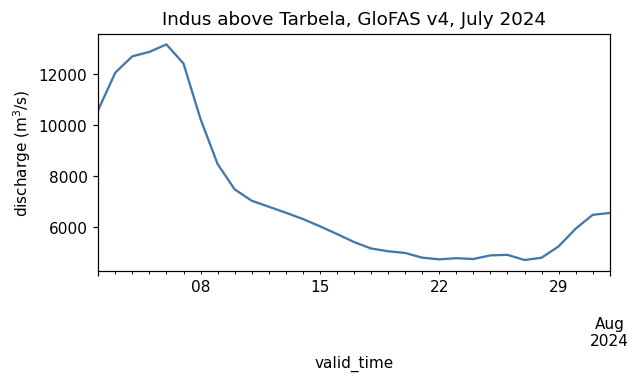

In [12]:
if HAVE_CDS:
    import cdsapi
    key = [l.split(":", 1)[1].strip() for l in (HOME / ".cdsapirc").read_text().splitlines() if l.startswith("key")][0]
    ewds = cdsapi.Client(url="https://ewds.climate.copernicus.eu/api", key=key, quiet=True, progress=False)
    target = DATA / "glofas_indus_2024_07.nc"
    if not target.exists():
        ewds.retrieve("cems-glofas-historical", {
            "system_version": ["version_4_0"], "hydrological_model": ["lisflood"], "product_type": ["consolidated"],
            "variable": ["average_river_discharge_in_the_last_24_hours"], "timespan": ["time_mean"],
            "year": ["2024"], "month": ["07"], "day": [f"{d:02d}" for d in range(1, 32)],
            "data_format": "netcdf", "download_format": "unarchived", "area": [35.2, 72.6, 34.7, 73.1]}, str(target))
    q = xr.open_dataset(target)
    dis = q[[n for n in q.data_vars if q[n].ndim == 3][0]]
    mean = dis.mean(dis.dims[0])
    lat, lon = np.unravel_index(int(mean.argmax()), mean.shape)        # the main channel carries the most water
    series = dis.isel(latitude=lat, longitude=lon).to_series()
    print(f"cell {float(q.latitude[lat]):.3f} N, {float(q.longitude[lon]):.3f} E;",
          f"July 2024 mean {series.mean():,.0f} m3/s, peak {series.max():,.0f} m3/s")
    series.plot(figsize=(6, 2.8), color="#4477aa", ylabel="discharge (m$^3$/s)", title="Indus above Tarbela, GloFAS v4, July 2024")
    plt.show()
else:
    print("No ~/.cdsapirc on this computer: see 'Signing up, step by step'.")

# Method 5: Google Earth Engine

Earth Engine turns the problem around: instead of downloading the data to your computer, you send your **program to
the data**. The code you write builds a description of a calculation; nothing runs until you ask for a result
(`getInfo()`), a picture, or an **export** (a file written to Google Drive, Cloud Storage or an Earth Engine asset).

Three limits shape how you work with it:

* an interactive request must finish within about five minutes, or it fails with *computation timed out*;
* very long chains of steps fail with *computation is too complex* (a loop over hundreds of days, for example): split
  the work, or export it as a **batch task**, which runs for hours in the background;
* the free non-commercial tier limits how many requests run at once. Too many fail with *Too Many Requests*;
  the cure is to wait and retry, as the last section shows.

In [13]:
EE_PROJECT = os.environ.get("EE_PROJECT")           # your Cloud project ID, e.g. set in a terminal: EE_PROJECT=ee-yourname
if HAVE_EE and EE_PROJECT:
    import ee
    ee.Initialize(project=EE_PROJECT)
    hunza = ee.Geometry.Rectangle(BBOX)
    col = ee.ImageCollection("MODIS/061/MOD10A1").filterDate("2024-10-01", "2025-10-01").select("NDSI_Snow_Cover")
    snow_days = col.map(lambda i: i.gte(40).unmask(0)).sum()            # days with snow
    clear_days = col.map(lambda i: i.mask().gt(0)).sum()                # days with a clear view
    stats = snow_days.rename("snow_days").addBands(clear_days.rename("clear_days")).reduceRegion(ee.Reducer.mean(), hunza, 500)
    print("Hunza valley box, October 2024 to September 2025, mean per pixel:", {k: round(v, 1) for k, v in stats.getInfo().items()})
    print("images in the collection:", col.size().getInfo())
else:
    print("Earth Engine not set up here: register a Cloud project, run 'earthengine authenticate',",
          "and set EE_PROJECT to the project ID.")

Hunza valley box, October 2024 to September 2025, mean per pixel: {'clear_days': 177.8, 'snow_days': 21.3}


images in the collection: 365


# Downloading in bulk

Research needs hundreds or thousands of files. Five habits make that safe:

1. **One request per file**, small enough to finish in minutes (a month, a year, a tile). A failure then costs one
   piece, not the whole job.
2. **Skip what is already done**, so the same script can simply be run again after an interruption.
3. **Wait and retry** when a server refuses with a temporary error (HTTP 429 *too many requests*, 503 *unavailable*),
   waiting longer each time (**exponential backoff**). Never retry at once in a tight loop: it makes the problem worse
   and can get your account blocked.
4. **Check every file** (size, and that it opens) before counting it as done.
5. **Write a manifest**: a table of every file with its source, date, size and checksum, and the dataset's licence and
   citation. It is what makes your data section reproducible.

The function below combines habits 2 to 4 for any download function; the next cell uses it to fetch three months of
GloFAS and writes the manifest.

In [14]:
def with_retries(fn, *args, tries=6, wait=10, **kw):
    """Call fn; on a temporary failure wait 10, 20, 40... seconds and try again."""
    for attempt in range(tries):
        try:
            return fn(*args, **kw)
        except Exception as e:                                            # narrow this to the library's own errors in real code
            temporary = any(s in str(e) for s in ("429", "503", "Too Many Requests", "timed out", "Connection"))
            if not temporary or attempt == tries - 1:
                raise
            print(f"  temporary failure ({str(e)[:60]}...), waiting {wait * 2 ** attempt} s")
            time.sleep(wait * 2 ** attempt)

def sha256(p):
    return hashlib.sha256(Path(p).read_bytes()).hexdigest()

manifest = []
if HAVE_CDS:
    for month in ["05", "06", "07"]:
        target = DATA / f"glofas_indus_2024_{month}.nc"
        if not target.exists():                                           # habit 2: skip what is done
            with_retries(ewds.retrieve, "cems-glofas-historical", {
                "system_version": ["version_4_0"], "hydrological_model": ["lisflood"], "product_type": ["consolidated"],
                "variable": ["average_river_discharge_in_the_last_24_hours"], "timespan": ["time_mean"],
                "year": ["2024"], "month": [month], "day": [f"{d:02d}" for d in range(1, 32)],
                "data_format": "netcdf", "download_format": "unarchived", "area": [35.2, 72.6, 34.7, 73.1]}, str(target))
        xr.open_dataset(target).close()                                   # habit 4: it opens
        manifest.append(dict(file=target.name, source="Copernicus EWDS, cems-glofas-historical v4.0",
                             bytes=target.stat().st_size, sha256=sha256(target)[:16],
                             licence="CEMS-FLOODS data licence", cite="doi:10.24381/cds.a4fdd6b9"))
manifest.append(dict(file=path.name, source="NOAA NCEI snow cover extent CDR v01r01", bytes=nbytes, sha256=sha[:16],
                     licence="no restrictions", cite="doi:10.7289/V5N014G9"))
manifest = pd.DataFrame(manifest)
manifest.to_csv(DATA / "manifest.csv", index=False)
manifest

,file,source,bytes,sha256,licence,cite
0,glofas_indus_2024_05.nc,"Copernicus EWDS, cems-glofas-historical v4.0",30501,363a8fa79dfe6da3,CEMS-FLOODS data licence,doi:10.24381/cds.a4fdd6b9
1,glofas_indus_2024_06.nc,"Copernicus EWDS, cems-glofas-historical v4.0",30502,723225237fe1e2f0,CEMS-FLOODS data licence,doi:10.24381/cds.a4fdd6b9
2,glofas_indus_2024_07.nc,"Copernicus EWDS, cems-glofas-historical v4.0",30891,c097fe52f94d2d7b,CEMS-FLOODS data licence,doi:10.24381/cds.a4fdd6b9
3,nhsce_v01r01_19661004_20261102.nc,NOAA NCEI snow cover extent CDR v01r01,24671777,c758f2764172f8b9,no restrictions,doi:10.7289/V5N014G9


# What to remember

* Find out **who holds** a dataset, **what licence** it carries and **how it is reached** (plain web, STAC,
  earthaccess, cdsapi, Earth Engine) before writing any analysis.
* Keep **secrets out of code**: credential files in your home folder, environment variables, Colab Secrets.
* **Read the metadata** of every file first: units, coded values, missing-data markers, licence.
* Read only **the part you need** (COG windows, small request areas), and **download in pieces** that can be skipped,
  retried and checked.
* Keep a **manifest**. Your methods section, and anyone repeating your work, will need it.

**Exercises.** (1) Change the STAC search to Landsat (`landsat-c2-l2`) and compare how many images each mission has
for the same months. (2) Use *earthaccess* to count MOD10A1F files for a whole year and estimate the download size for
the tiles covering your own country. (3) Request ERA5-Land monthly 2 m temperature (`reanalysis-era5-land-monthly-means`)
for a box of your choice, and add it to the manifest with its licence and citation.